**Импорт используемых библиотек**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

# Импорты машинного обучения
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

**Чтение файла и загрузка его в дата фрейм**

In [2]:
df = pd.read_csv('survey lung cancer.csv')

**Смотрю заголовки, проверяя что все правильно загрузилось, запросив 4 строки**

In [3]:
df.head(4)

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER
0,M,69,1,2,2,1,1,2,1,2,2,2,2,2,2,YES
1,M,74,2,1,1,1,2,2,2,1,1,1,2,2,2,YES
2,F,59,1,1,1,2,1,2,1,2,1,2,2,1,2,NO
3,M,63,2,2,2,1,1,1,1,1,2,1,1,2,2,NO


**Проверяю дубликаты и пустые значения с целью предобработки данных**

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   GENDER                 309 non-null    str  
 1   AGE                    309 non-null    int64
 2   SMOKING                309 non-null    int64
 3   YELLOW_FINGERS         309 non-null    int64
 4   ANXIETY                309 non-null    int64
 5   PEER_PRESSURE          309 non-null    int64
 6   CHRONIC DISEASE        309 non-null    int64
 7   FATIGUE                309 non-null    int64
 8   ALLERGY                309 non-null    int64
 9   WHEEZING               309 non-null    int64
 10  ALCOHOL CONSUMING      309 non-null    int64
 11  COUGHING               309 non-null    int64
 12  SHORTNESS OF BREATH    309 non-null    int64
 13  SWALLOWING DIFFICULTY  309 non-null    int64
 14  CHEST PAIN             309 non-null    int64
 15  LUNG_CANCER            309 non-null    str  
dtypes

In [5]:
duplicates_count = df.duplicated().sum()
print (f'Количество найденных дубликатов : {duplicates_count}')
df = df.drop_duplicates()
print("Размер после удаления:", df.shape)

Количество найденных дубликатов : 33
Размер после удаления: (276, 16)


In [6]:
df.describe()

,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN
count,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000,276.000000
mean,62.909420,1.543478,1.576087,1.496377,1.507246,1.521739,1.663043,1.547101,1.547101,1.550725,1.576087,1.630435,1.467391,1.557971
std,8.379355,0.499011,0.495075,0.500895,0.500856,0.500435,0.473529,0.498681,0.498681,0.498324,0.495075,0.483564,0.499842,0.497530
min,21.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,57.750000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,62.500000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,2.000000
75%,69.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
max,87.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000


**ПЕРВИЧНЫЙ АНАЛИЗ ЗАВЕРШЕН**

**EDA анализ**

In [7]:
df['LUNG_CANCER'].value_counts()

LUNG_CANCER
YES    238
NO      38
Name: count, dtype: int64

**Смотрю, сколько людей в каждой категории**

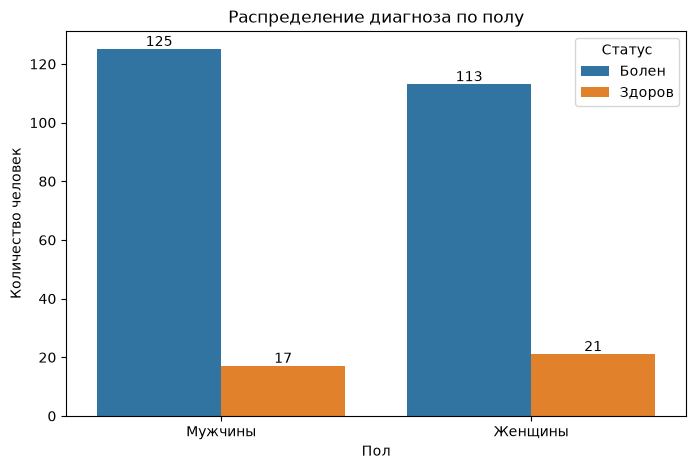

In [ ]:
#  размер картинки 
plt.figure(figsize=(8, 5))

df[ 'GENDER_TEXT'] = df['GENDER'].map({'M':'Мужчины', 'F':'Женщины'})
df['LUNG_CANCER_TEXT'] = df['LUNG_CANCER'].map({'YES':'Болен', 'NO':'Здоров'})
# график
ax = sns.countplot(data=df, x='GENDER_TEXT', hue='LUNG_CANCER_TEXT')
# заголовок
plt.title('Распределение диагноза по полу')
plt.xlabel('Пол')
plt.ylabel('Количество человек')
plt.legend(title='Статус')
for container in ax.containers:
    ax.bar_label(container)
plt.show()

**Из графика видно, что доля больных среди мужчин выше, чем среди женщин**

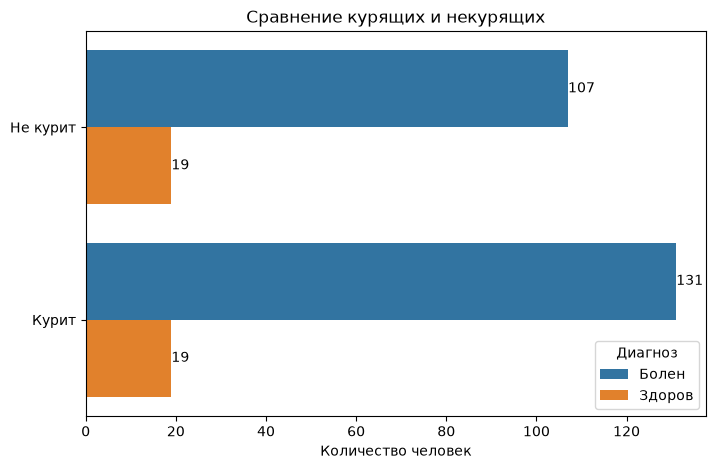

In [ ]:
plt.figure(figsize=(8, 5))

# кодирование значения 1 и 2 на текст для графика
df['SMOKING_TEXT'] = df['SMOKING'].map({1: 'Не курит', 2: 'Курит'})

df['LUNG_CANCER_TEXT'] = df['LUNG_CANCER'].map({'YES':'Болен', 'NO':'Здоров'})
# график
ax = sns.countplot(data=df, y='SMOKING_TEXT', hue='LUNG_CANCER_TEXT')

plt.title('Сравнение курящих и некурящих')
plt.xlabel('Количество человек')
plt.ylabel('') 
plt.legend(title='Диагноз')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

**Курящие пациенты болеют чаще, но также наблюдается высокая доля больных среди некурящих, что может говорить о других факторах риска**

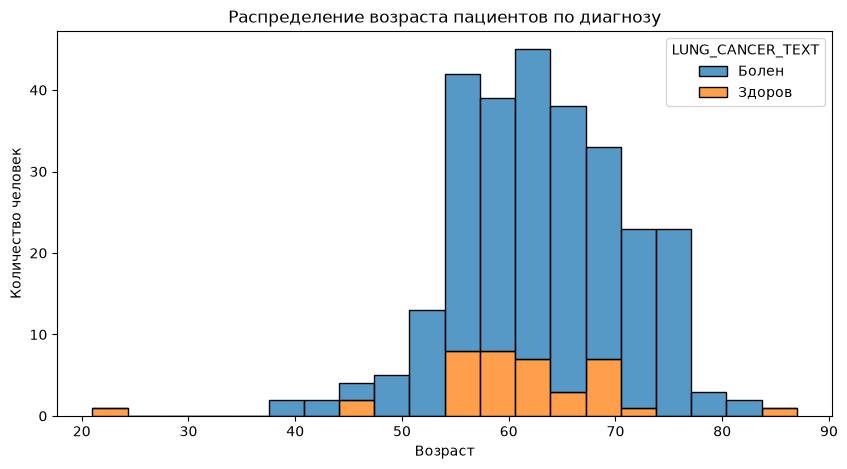

In [10]:
plt.figure(figsize=(10,5))
sns.histplot(data = df , x = 'AGE', hue= 'LUNG_CANCER_TEXT', bins=20 , multiple="stack")
plt.title ('Распределение возраста пациентов по диагнозу')
plt.xlabel ('Возраст')
plt.ylabel ('Количество человек')
plt.show()

**Пик заболеваемости приходит на возраст 60-70 лет. Люди возрастом 50-60 находятся в зоне повышенного риска.**

In [11]:
df['GENDER'] = df["GENDER"].map({'M': 1, 'F': 0})
df['LUNG_CANCER'] = df['LUNG_CANCER'].map({'YES': 1, 'NO': 0})
df.head()

,GENDER,AGE,SMOKING,YELLOW_FINGERS,ANXIETY,PEER_PRESSURE,CHRONIC DISEASE,FATIGUE,ALLERGY,WHEEZING,ALCOHOL CONSUMING,COUGHING,SHORTNESS OF BREATH,SWALLOWING DIFFICULTY,CHEST PAIN,LUNG_CANCER,GENDER_TEXT,LUNG_CANCER_TEXT,SMOKING_TEXT
0,1,69,1,2,2,1,1,2,1,2,2,2,2,2,2,1,Мужчины,Болен,Не курит
1,1,74,2,1,1,1,2,2,2,1,1,1,2,2,2,1,Мужчины,Болен,Курит
2,0,59,1,1,1,2,1,2,1,2,1,2,2,1,2,0,Женщины,Здоров,Не курит
3,1,63,2,2,2,1,1,1,1,1,2,1,1,2,2,0,Мужчины,Здоров,Курит
4,0,63,1,2,1,1,1,1,1,2,1,2,2,1,1,0,Женщины,Здоров,Не курит


**Выполнила кодирование категориальных признаков, с целью нормализации данных, для последующего обучения модели**

In [12]:
df.columns

Index(['GENDER', 'AGE', 'SMOKING', 'YELLOW_FINGERS', 'ANXIETY',
       'PEER_PRESSURE', 'CHRONIC DISEASE', 'FATIGUE ', 'ALLERGY ', 'WHEEZING',
       'ALCOHOL CONSUMING', 'COUGHING', 'SHORTNESS OF BREATH',
       'SWALLOWING DIFFICULTY', 'CHEST PAIN', 'LUNG_CANCER', 'GENDER_TEXT',
       'LUNG_CANCER_TEXT', 'SMOKING_TEXT'],
      dtype='str')

**Удалила текстовые колонки для чистоты данных**

In [ ]:
# X то, по чему мы предсказываем (все колонки, кроме диагноза)
# y то, что мы предсказываем (сам диагноз)
X = df.drop(columns=['LUNG_CANCER', 'GENDER_TEXT', 'LUNG_CANCER_TEXT', 'SMOKING_TEXT'])
y = df['LUNG_CANCER']

# размер для проверки
print("Размер X:", X.shape)
print("Размер y:", y.shape)

Размер X: (276, 15)
Размер y: (276,)


**Отделила признаки от целевой модели**

In [ ]:
# 80% данных — на обучение, 20% — на тест
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

**Отделила данные для обучения и данные на тестирование**

In [15]:
# Создаем модель
model = LogisticRegression(max_iter=1000)

# Обучаем её на тренировочных данных
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [16]:
from sklearn.metrics import accuracy_score, classification_report

# Делаем предсказания на тестовых данных (которые модель не видела)
y_pred = model.predict(X_test)

# Выводим метрики
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\nОтчет по классификации:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.911

Отчет по классификации:

              precision    recall  f1-score   support

           0       0.80      0.50      0.62         8
           1       0.92      0.98      0.95        48

    accuracy                           0.91        56
   macro avg       0.86      0.74      0.78        56
weighted avg       0.90      0.91      0.90        56



**Оценка модели:**
Модель логистической регрессии показала *высокую общую точность (Accuracy = 0.91)*.
Однако из-за сильного дисбаланса классов (87% больных против 13% здоровых) метрика *Recall для класса "Здоров" составила всего 0.50*. Это означает, что модель пропускает половину здоровых пациентов, ошибочно классифицируя их как больных.
Для улучшения модели необходимо применить методы балансировки классов.

**Улучшение модели (Эксперимент)**
Попробую решить проблему дисбаланса классов с помощью параметра `class_weight='balanced'`.
Параметр заставит модель автоматически присваивать больший вес редкому классу (здоровые пациенты) и меньший вес частому классу (больные). 
Затем обучаю НОВУЮ модель и сравнаю результаты.

In [17]:
# 1. Создаем новую модель с балансировкой классов
model_balanced = LogisticRegression(max_iter=1000, class_weight='balanced')

# 2. Обучаем её на тех же тренировочных данных
model_balanced.fit(X_train, y_train)

# 3. Делаем предсказания
y_pred_balanced = model_balanced.predict(X_test)

# 4. Выводим метрики
print("Accuracy (с балансировкой):", round(accuracy_score(y_test, y_pred_balanced), 3))
print("\nОтчет по классификации (с балансировкой):\n")
print(classification_report(y_test, y_pred_balanced))

Accuracy (с балансировкой): 0.875

Отчет по классификации (с балансировкой):

              precision    recall  f1-score   support

           0       0.53      1.00      0.70         8
           1       1.00      0.85      0.92        48

    accuracy                           0.88        56
   macro avg       0.77      0.93      0.81        56
weighted avg       0.93      0.88      0.89        56



### Итоги эксперимента: Сравнение базовой и сбалансированной моделей

В ходе эксперимента был пременен параметр `class_weight='balanced'` к логистической регрессии, чтобы решить проблему сильного дисбаланса классов (238 больных против 38 здоровых), для последующего сравнения полученных метрик с базовой моделью.

*1. Что изменилось в цифрах:*
- Accuracy (Общая точность): Снизилась с *0.911* до *0.875*. Это ожидаемо, так как модель перестала «подстраиваться» под большинство и начала обращать больше внимания на меньшинство.
- Recall для класса «Здоров (0)»: Вырос с *0.50* до *1.00*. Теперь модель находит *100% здоровых пациентов* (не пропускает ни одного).
- Precision для класса «Здоров (0)»: Упал с *0.80* до *0.53*. Это значит, что модель стала чаще ошибаться, называя больных людей здоровыми (появилось больше ложноположительных срабатываний).
= Recall для класса «Болен (1)»: Снизился с *0.98** до *0.85*. Мы немного пожертвовали способностью находить больных, чтобы лучше находить здоровых.

*2. Интерпретация для медицинской практики (Ключевой вывод):*
В медицинских задачах выбор модели зависит от бизнес-цели:
Если целью является *первичный скрининг*  (не пропустить ни одного больного), лучше подходит *базовая модель*, так как *у нее выше Recall для больных (0.98)*.
Если целью являются *подтверждающая диагностика* (не пугать здоровых людей лишними обследованиями), лучше подходит *сбалансированная модель, так как она находит здоровых с коэфицентом (Recall = 1.00)*, хотя и ценой ложных тревог (Precision = 0.53).

*Вывод*
Метрика Accuracy в условиях дисбаланса классов обманчива. Использование `class_weight='balanced'` позволило сделать модель более чувствительной к редкому классу. Для реального внедрения в клиническую практику нам необходимо дополнительно подобрать порог отсечения (threshold) или найти компромисс между Precision и Recall с помощью F1-меры (которая для здоровых выросла с 0.62 до 0.70).

### Визуализация ошибок модели
Посроение матрицы ошибок (Confusion Matrix) для сбалансированной модели, чтобы наглядно увидеть, сколько здоровых и больных пациентов модель классифицировала верно, а сколько ошибочно.

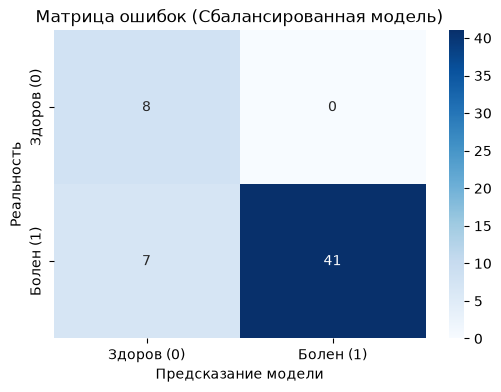

In [18]:
from sklearn.metrics import confusion_matrix

# Строим матрицу ошибок для сбалансированной модели
cm = confusion_matrix(y_test, y_pred_balanced)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Здоров (0)', 'Болен (1)'], 
            yticklabels=['Здоров (0)', 'Болен (1)'])
plt.xlabel('Предсказание модели')
plt.ylabel('Реальность')
plt.title('Матрица ошибок (Сбалансированная модель)')
plt.show()

### Анализ матрицы ошибок (Сбалансированная модель)

Построенная матрица ошибок (Confusion Matrix) для тестовой выборки (56 пациентов) позволяет детально оценить качество сбалансированной модели.

*Как читать матрицу:*
- Строки — это реальный статус пациента (Здоров / Болен).
- Столбцы — это то, что предсказала модель.
- По диагонали (8 и 41) — правильные предсказания модели.
- Вне диагонали (0 и 7) — ошибки.

*Детальный разбор результатов:*

1.  True Positives (41): Модель верно распознала 41 больного пациента. Это отличный показатель.
2.  True Negatives (8): Модель верно распознала 8 здоровых пациентов.
3.  False Positives (7): 7 здоровых пациентов были ошибочно классифицированы как больные (ложная тревога).
4.  False Negatives (0): Модель не пропустила ни одного больного человека. 

Интерпретация для клинической практики:
С точки зрения медицинского скрининга, такая модель является безопасной. Самая критичная ошибка в диагностике — это False Negative (когда больному говорят, что он здоров, и он не получает лечения). Эта модель показывает 0 пропущенных больных.

Мы получили 7 ложноположительных срабатываний (False Positive), что означает, что 7 здоровых людей отправятся на дополнительные обследования. Однако в медицинской практике лучше перестраховаться и провести лишний тест, чем пропустить развитие смертельного заболевания. 

*Вывод:*
Сбалансированная модель (с `class_weight='balanced'`) подходит для задач первичного скрининга, где главная цель — это не упустить ни одного пациента с патологией.

### Анализ важности признаков
Посмотрим, какие факторы (возраст, курение, симптомы) оказали наибольшее влияние на решение модели. Для этого извлечем коэффициенты (`coef_`) из обученной логистической регрессии.

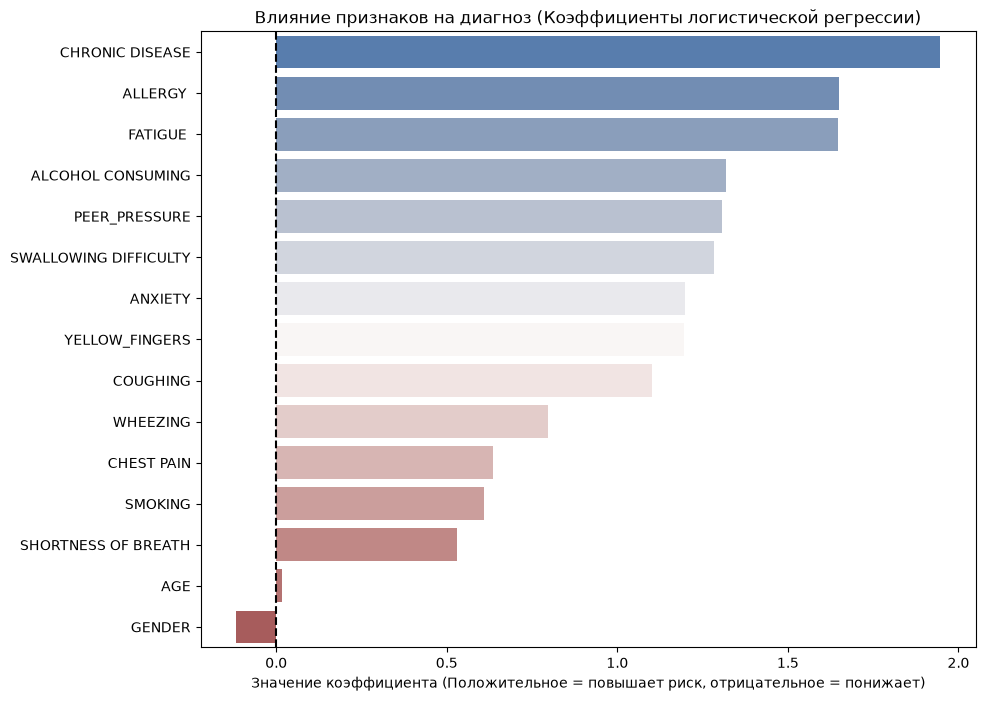

In [21]:
# Достаем коэффициенты из сбалансированной модели
coefficients = model_balanced.coef_[0]

# Создаем DataFrame для удобной сортировки
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coefficients
})

# Сортируем по убыванию (самые важные сверху)
feature_importance = feature_importance.sort_values(by='Coefficient', ascending=False)

# Строим горизонтальный график
plt.figure(figsize=(10, 8))
sns.barplot(data=feature_importance, x='Coefficient', y='Feature', hue='Feature', palette='vlag', legend=False)
plt.title('Влияние признаков на диагноз (Коэффициенты логистической регрессии)')
plt.xlabel('Значение коэффициента (Положительное = повышает риск, отрицательное = понижает)')
plt.ylabel('')
plt.axvline(x=0, color='black', linestyle='--') # Линия нуля
plt.show()

**Анализ важности признаков (Feature Importance)**
На графике представлены коэффициенты обученной модели логистической регрессии (`coef_`). Они показывают направление и силу влияния каждого признака на вероятность постановки диагноза.

*Как читать график:*

-  Положительные значения (столбцы вправо от нуля) — признак повышает вероятность диагноза «болен».

- Отрицательные значения (столбцы влево от нуля) — признак снижает вероятность диагноза.

- Длина столбца — чем длиннее столбец, тем сильнее признак влияет на решение модели.

*Ключевые наблюдения:*

- Самый сильный фактор риска — хронические заболевания (CHRONIC DISEASE). Он имеет самый высокий положительный коэффициент. Это логично: наличие хронических болезней значительно повышает уязвимость пациента.

- Аллергия (ALLERGY) и усталость (FATIGUE) также показывают высокое положительное влияние. В медицинском контексте это может говорить о том, что данные симптомы часто сопровождают развитие патологии.

- Курение (SMOKING) и одышка (SHORTNESS OF BREATH) находятся в верхней половине графика, подтверждая известные медицинские факты о факторах риска.

- Пол (GENDER) имеет отрицательный коэффициент. В контексте данного кодирования (1 — мужчина, 0 — женщина) это означает, что при прочих равных модель считает женщин (0) более склонными к диагнозу «болен» в рамках данного конкретного датасета. (*Примечание:* это особенность выборки, а не общий медицинский вывод).

- Возраст (AGE) имеет очень маленький коэффициент. Это важно, ведь визуально (на предыдущем графике) пик заболеваемости приходится на 60–70 лет, для модели сам по себе возраст оказался менее значимым, чем наличие хронических болезней или аллергии.

*Ограничения интерпретации:*
Стоит отметить, что признаки в датасете имеют разный масштаб (возраст измеряется десятками лет, а симптомы — бинарные 1/2). Из-за этого коэффициенты нельзя сравнивать напрямую как «силу влияния одного года возраста» против «наличия симптома». Для более строгого анализа необходимо было бы провести стандартизацию признаков (`StandardScaler`).

*Вывод для врачей:*
Модель подтверждает, что наибольшее внимание при скрининге стоит уделять пациентам с хроническими заболеваниями, аллергиями и усталостью, а также курящим. Пол и возраст в рамках данной выборки оказались менее значимыми предикторами.